
СЧИТАЕМ (Юкава): Плотность = 10.0%, Сигма = 2.0, J0 = 3.0
     Шаг |  density |    P_inf |  Perimeter | Max_Size | Time(s)
-----------------------------------------------------------------
  250000 |    0.096 |    0.324 |      532.0 |      312 |   492.6


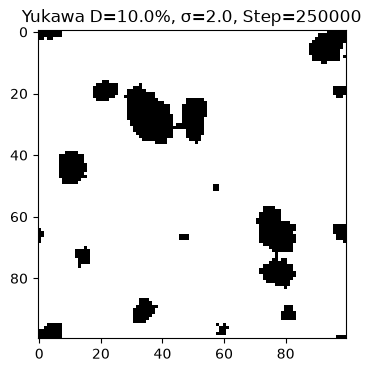

  500000 |    0.096 |    0.366 |      408.0 |      353 |  1012.2


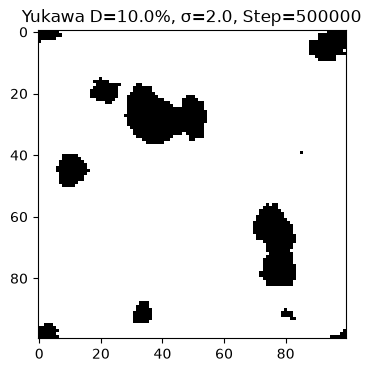

  750000 |    0.096 |    0.383 |      352.0 |      369 |  1537.9


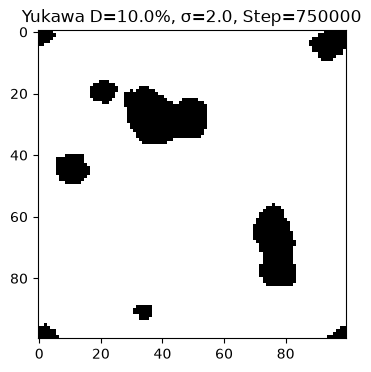

 1000000 |    0.096 |    0.408 |      334.0 |      393 |  2041.5


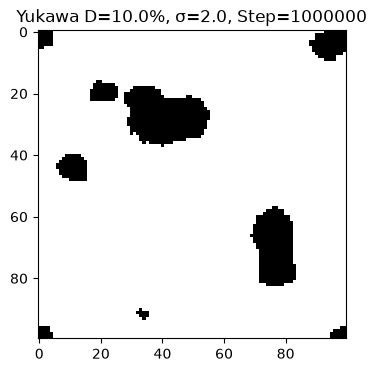

 1250000 |    0.096 |    0.411 |      308.0 |      396 |  2552.1


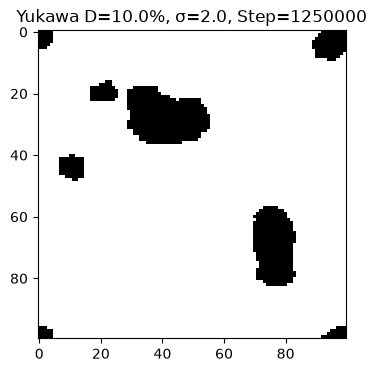

 1500000 |    0.096 |    0.411 |      302.0 |      396 |  3046.7


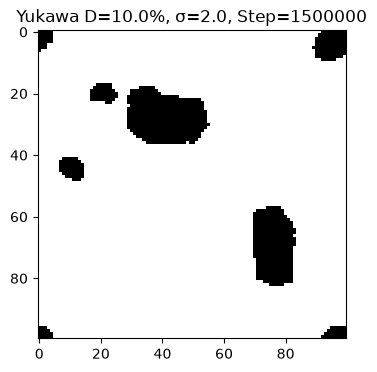

 1750000 |    0.096 |    0.423 |      290.0 |      408 |  3524.3


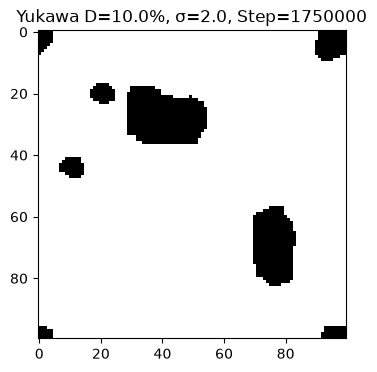

 2000000 |    0.096 |    0.433 |      284.0 |      417 |  4053.3


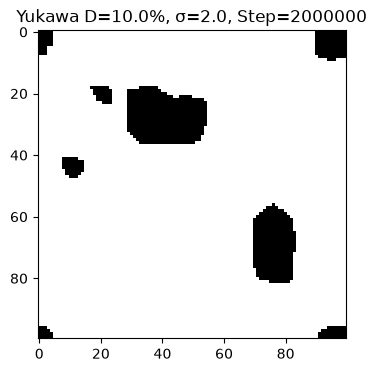

 2250000 |    0.096 |    0.436 |      278.0 |      420 |  4664.7


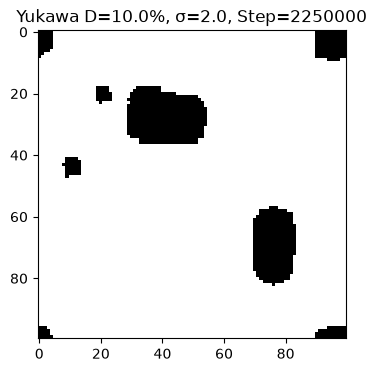

ТОЧКА ЗАВЕРШЕНА.

СЧИТАЕМ (Юкава): Плотность = 10.0%, Сигма = 10.0, J0 = 3.0
     Шаг |  density |    P_inf |  Perimeter | Max_Size | Time(s)
-----------------------------------------------------------------
  250000 |    0.100 |    0.178 |      572.0 |      178 |   454.3


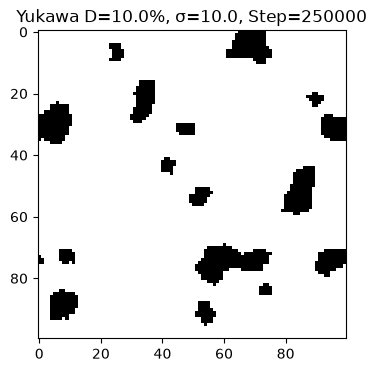

  500000 |    0.100 |    0.215 |      484.0 |      215 |   909.6


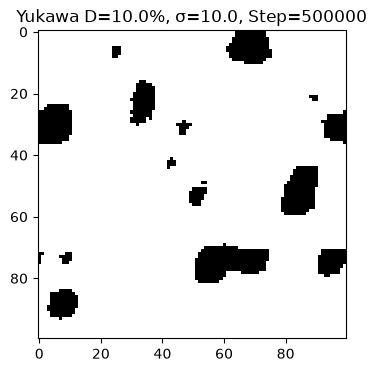

  750000 |    0.100 |    0.239 |      412.0 |      239 |  1363.0


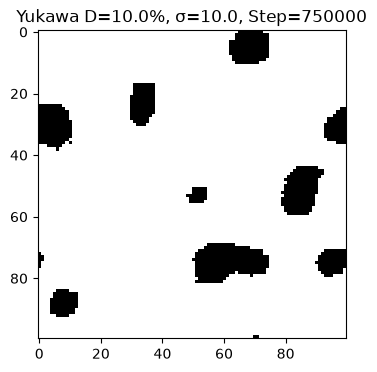

 1000000 |    0.100 |    0.251 |      386.0 |      252 |  1825.3


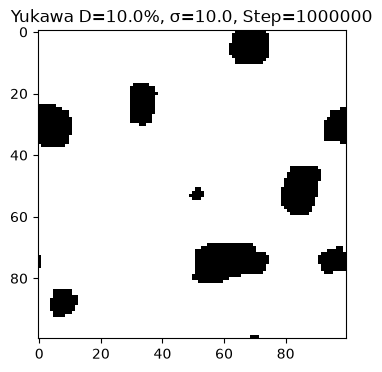

 1250000 |    0.100 |    0.265 |      374.0 |      266 |  2273.6


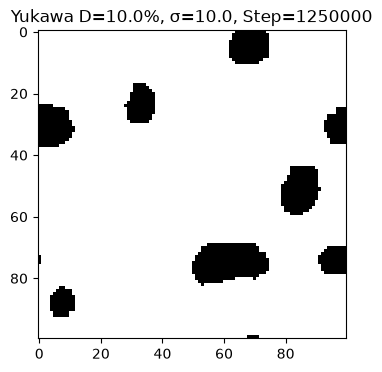

 1500000 |    0.100 |    0.283 |      362.0 |      284 |  2722.0


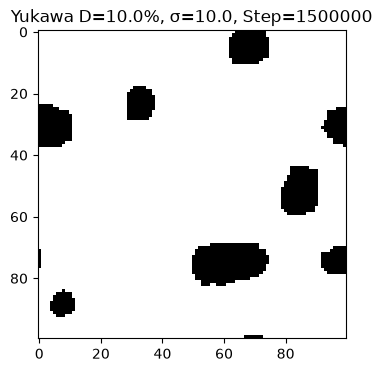

 1750000 |    0.100 |    0.283 |      356.0 |      284 |  3178.9


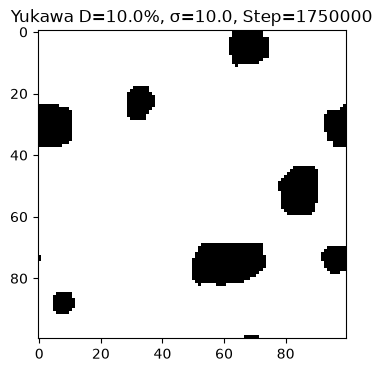

 2000000 |    0.100 |    0.286 |      352.0 |      287 |  3625.7


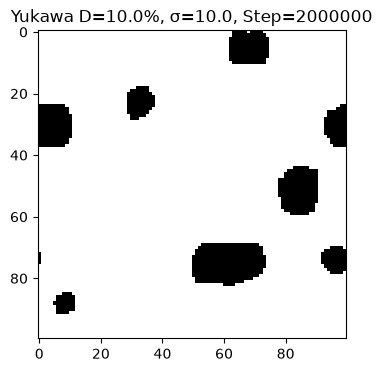

 2250000 |    0.100 |    0.290 |      348.0 |      291 |  4090.4


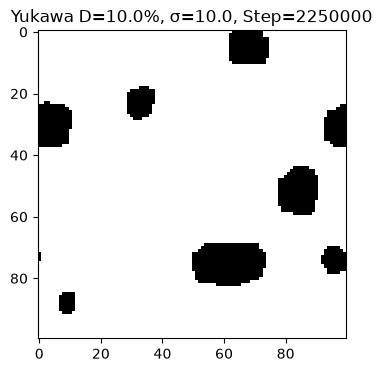

ТОЧКА ЗАВЕРШЕНА.

СЧИТАЕМ (Юкава): Плотность = 50.0%, Сигма = 1.5, J0 = 3.0
     Шаг |  density |    P_inf |  Perimeter | Max_Size | Time(s)
-----------------------------------------------------------------
  250000 |    0.499 |    0.896 |     1326.0 |     4473 |   911.3


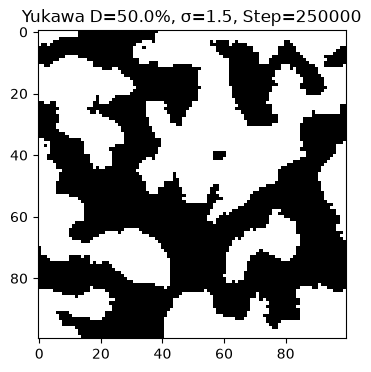

  500000 |    0.499 |    0.910 |     1076.0 |     4543 |  1753.9


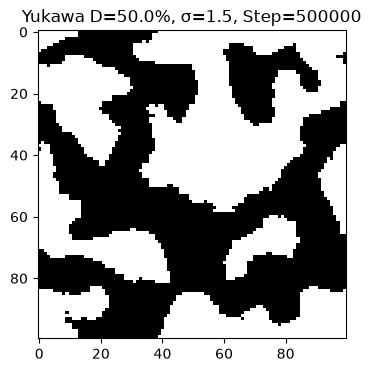

  750000 |    0.499 |    0.913 |      972.0 |     4558 |  2584.5


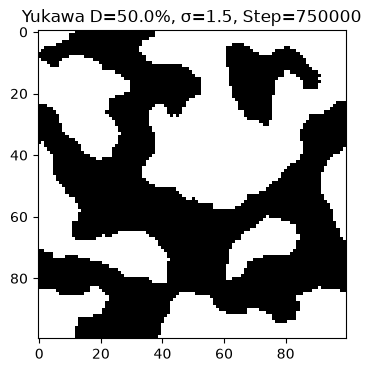

 1000000 |    0.499 |    0.916 |      906.0 |     4572 |  3416.2


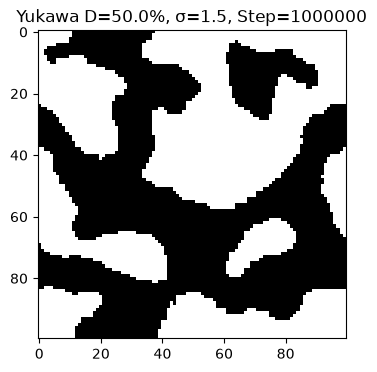

 1250000 |    0.499 |    0.918 |      868.0 |     4581 |  4238.4


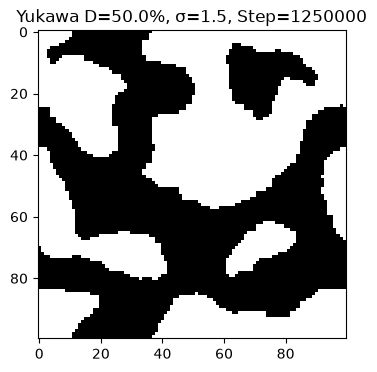

 1500000 |    0.499 |    0.923 |      828.0 |     4609 |  5043.2


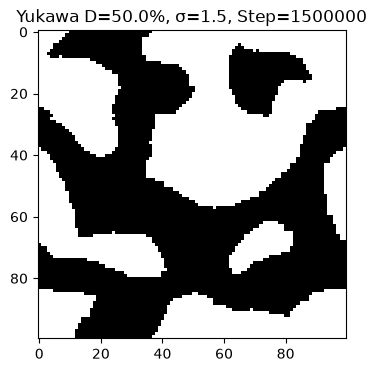

ТОЧКА ЗАВЕРШЕНА.

СЧИТАЕМ (Юкава): Плотность = 50.0%, Сигма = 2.0, J0 = 3.0
     Шаг |  density |    P_inf |  Perimeter | Max_Size | Time(s)
-----------------------------------------------------------------
  250000 |    0.498 |    0.717 |     1368.0 |     3570 |   929.0


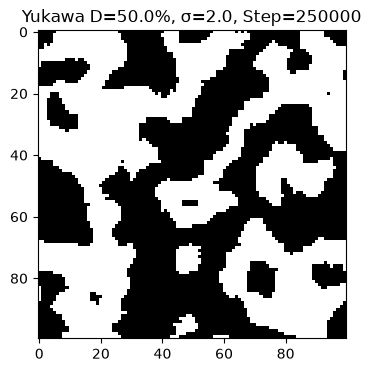

  500000 |    0.498 |    0.744 |     1138.0 |     3704 |  1742.4


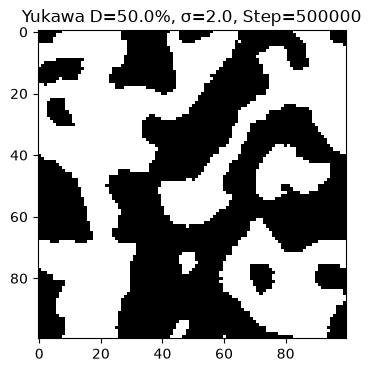

  750000 |    0.498 |    0.762 |     1020.0 |     3791 |  2577.8


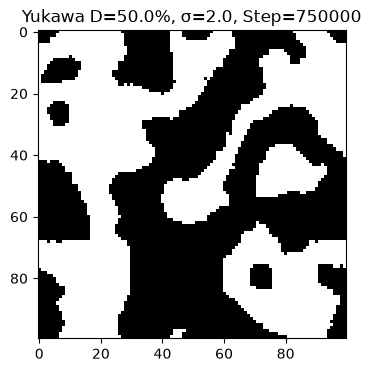

In [ ]:
# ============================================================
# DEEP_DIVE_YUKAWA_V2: 4 ТОЧКИ (1 МЛН ШАГОВ) С ПОЛНЫМИ ЧЕКПОИНТАМИ
# ============================================================

import numpy as np
from scipy.ndimage import label
import matplotlib
matplotlib.use('Agg') 
import matplotlib.pyplot as plt
import csv
import time
import os
from IPython.display import display, Image as IPImage

# ------------------------------------------------------------
# REM: ПАПКИ ДЛЯ РЕЗУЛЬТАТОВ И ЧЕКПОИНТОВ
# ------------------------------------------------------------
output_dir = "DEEP_DIVE_YUKAWA_V2"
csv_dir = os.path.join(output_dir, "csv")
png_dir = os.path.join(output_dir, "png")
ckpt_dir = os.path.join(output_dir, "checkpoints")
os.makedirs(output_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)
os.makedirs(png_dir, exist_ok=True)
os.makedirs(ckpt_dir, exist_ok=True)

# ------------------------------------------------------------
# REM: ПАРАМЕТРЫ
# ------------------------------------------------------------
L = 100
STEPS = 500_000  # 500 тыс шагов
beta = 1.0
J0 = 3.0
mu = 0.5
r_cutoff = 4

POINTS = [
    (0.10, 2.0),   
    (0.10, 10.0),  
    (0.50, 1.5),   
    (0.50, 2.0)    
]

csv_file = os.path.join(csv_dir, "deep_dive_yukawa_v2.csv")

if not os.path.exists(csv_file):
    with open(csv_file, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['p_init', 'J0', 'sigma', 'step', 'density', 'P_inf', 'perimeter', 'max_size'])

# ------------------------------------------------------------
# REM: ФУНКЦИИ
# ------------------------------------------------------------

def init_lattice(L, p):
    return (np.random.random((L, L)) < p).astype(int)

def make_yukawa_kernel(r_cut, mu, J0_val):
    size = 2 * r_cut + 1
    kernel = np.zeros((size, size))
    for i in range(size):
        for j in range(size):
            dx, dy = i - r_cut, j - r_cut
            r = np.sqrt(dx**2 + dy**2)
            if r > 0 and r <= r_cut:
                kernel[i, j] = J0_val * np.exp(-mu * r) / r
    return kernel

def get_local_window_torus(grid, i, j, r_cut):
    L = grid.shape[0]
    window = np.zeros((2*r_cut+1, 2*r_cut+1))
    for di in range(-r_cut, r_cut+1):
        for dj in range(-r_cut, r_cut+1):
            window[di + r_cut, dj + r_cut] = grid[(i + di) % L, (j + dj) % L]
    return window

def local_energy(grid, i, j, kernel, r_cut):
    # REM: Считает энергию взаимодействия ОДНОГО узла с его окружением.
    win = get_local_window_torus(grid, i, j, r_cut)
    return -np.sum(win * kernel)

def get_local_perimeter_both(grid, i1, j1, i2, j2, radius=2):
    L = grid.shape[0]
    p = 0
    min_i, max_i = min(i1, i2) - radius, max(i1, i2) + radius
    min_j, max_j = min(j1, j2) - radius, max(j1, j2) + radius
    for i in range(min_i, max_i + 1):
        for j in range(min_j, max_j + 1):
            ni, nj = i % L, j % L
            if grid[ni, nj] == 1:
                if grid[(ni-1)%L, nj] == 0: p += 1
                if grid[(ni+1)%L, nj] == 0: p += 1
                if grid[ni, (nj-1)%L] == 0: p += 1
                if grid[ni, (nj+1)%L] == 0: p += 1
    return p

def metropolis_step_yukawa(grid, sigma, yukawa_kernel, beta=1.0):
    L = grid.shape[0]
    while True:
        i1, j1 = np.random.randint(0, L, 2)
        if grid[i1, j1] == 1: break
    while True:
        i2, j2 = np.random.randint(0, L, 2)
        if grid[i2, j2] == 0: break

    # REM: Энергия ДО (считаем только для занятого i1, так как i2 пуст)
    E_old = local_energy(grid, i1, j1, yukawa_kernel, r_cutoff)
    P_old = get_local_perimeter_both(grid, i1, j1, i2, j2)

    # REM: Обмен
    grid[i1, j1] = 0
    grid[i2, j2] = 1

    # REM: Энергия ПОСЛЕ (считаем только для занятого i2, так как i1 пуст)
    E_new = local_energy(grid, i2, j2, yukawa_kernel, r_cutoff)
    P_new = get_local_perimeter_both(grid, i1, j1, i2, j2)

    delta_S = (E_new - E_old) + sigma * (P_new - P_old)

    if delta_S <= 0 or np.random.random() < np.exp(-beta * delta_S):
        return True
    else:
        grid[i1, j1] = 1
        grid[i2, j2] = 0
        return False

def measure(grid):
    padded = np.pad(grid, pad_width=1, mode='wrap')
    labeled, n = label(padded, structure=[[0,1,0],[1,1,1],[0,1,0]])
    labeled = labeled[1:-1, 1:-1]
    sizes = np.bincount(labeled.ravel())
    sizes[0] = 0
    sizes = sizes[sizes > 0]
    if len(sizes) == 0: return None
    
    P_inf = float(sizes.max() / np.sum(sizes))
    density = float(np.mean(grid))
    right = np.roll(grid, 1, axis=1); left = np.roll(grid, -1, axis=1)
    up = np.roll(grid, 1, axis=0); down = np.roll(grid, -1, axis=0)
    perimeter = int(np.sum((grid == 1) & (right == 0)) + np.sum((grid == 1) & (left == 0)) + 
                    np.sum((grid == 1) & (up == 0)) + np.sum((grid == 1) & (down == 0)))
    
    return {'density': density, 'P_inf': P_inf, 'perimeter': perimeter, 'max_size': int(sizes.max())}

# ------------------------------------------------------------
# REM: ЗАПУСК С ПОДДЕРЖКОЙ ВОССТАНОВЛЕНИЯ
# ------------------------------------------------------------
yukawa_kernel = make_yukawa_kernel(r_cutoff, mu, J0)

for p, sigma in POINTS:
    ckpt_grid_file = os.path.join(ckpt_dir, f"grid_p{p}_s{sigma}.npy")
    ckpt_step_file = os.path.join(ckpt_dir, f"step_p{p}_s{sigma}.npy")
    
    start_step = 0
    grid = None
    
    # REM: Проверяем наличие сохраненной сетки
    if os.path.exists(ckpt_grid_file) and os.path.exists(ckpt_step_file):
        grid = np.load(ckpt_grid_file)
        start_step = int(np.load(ckpt_step_file)[0])
        print(f"\n[RESTART] Плотность {p*100}%, Сигма {sigma}. Восстанавливаем с шага {start_step*5}...", flush=True)
    elif os.path.exists(csv_file):
        # REM: Проверяем, не завершена ли точка
        is_done = False
        with open(csv_file, 'r') as f:
            reader = csv.reader(f)
            next(reader, None)
            for row in reader:
                if len(row) >= 4 and abs(float(row[0]) - p) < 1e-5 and abs(float(row[2]) - sigma) < 1e-5:
                    if int(row[3]) == STEPS * 5: is_done = True
        if is_done:
            print(f"[SKIP] Плотность {p*100}%, Сигма {sigma} уже полностью посчитана.", flush=True)
            continue
        else:
            grid = init_lattice(L, p)
    else:
        grid = init_lattice(L, p)

    print("\n" + "="*65, flush=True)
    print(f"СЧИТАЕМ (Юкава): Плотность = {p*100}%, Сигма = {sigma}, J0 = {J0}", flush=True)
    print("="*65, flush=True)
    print(f"{'Шаг':>8} | {'density':>8} | {'P_inf':>8} | {'Perimeter':>10} | {'Max_Size':>8} | {'Time(s)':>7}", flush=True)
    print("-" * 65, flush=True)

    t0 = time.time()
    
    # REM: Цикл начинается с start_step, если произошло восстановление
    for step in range(start_step, STEPS):
        for _ in range(5):
            metropolis_step_yukawa(grid, sigma, yukawa_kernel, beta)
        
        real_step = step * 5
        
        # REM: Сохраняем чекпоинт каждые 250 тыс. шагов
        if real_step % 250_000 == 0 and real_step > 0:
            m = measure(grid)
            elapsed = time.time() - t0
            
            # Сохраняем в CSV
            with open(csv_file, 'a', newline='') as f:
                writer = csv.writer(f)
                writer.writerow([p, J0, sigma, real_step, m['density'], m['P_inf'], m['perimeter'], m['max_size']])
            
            print(f"{real_step:>8} | {m['density']:>8.3f} | {m['P_inf']:>8.3f} | {m['perimeter']:>10.1f} | {m['max_size']:>8d} | {elapsed:>7.1f}", flush=True)
            
            # Сохраняем сетку и шаг на диск
            np.save(ckpt_grid_file, grid)
            np.save(ckpt_step_file, np.array([step]))
            
            # Сохраняем картинку
            fig, ax = plt.subplots(figsize=(4, 4))
            ax.imshow(grid, cmap='binary', interpolation='nearest')
            ax.set_title(f'Yukawa D={p*100}%, σ={sigma}, Step={real_step}')
            img_path = os.path.join(png_dir, f"Y_D{p}_S{sigma}_step{real_step}.png")
            plt.savefig(img_path, dpi=100, bbox_inches='tight')
            plt.close(fig)
            display(IPImage(filename=img_path))

    # REM: Финальный замер и очистка чекпоинтов
    m = measure(grid)
    with open(csv_file, 'a', newline='') as f:
        writer = csv.writer(f)
        writer.writerow([p, J0, sigma, STEPS*5, m['density'], m['P_inf'], m['perimeter'], m['max_size']])
    
    if os.path.exists(ckpt_grid_file): os.remove(ckpt_grid_file)
    if os.path.exists(ckpt_step_file): os.remove(ckpt_step_file)
    
    print(f"ТОЧКА ЗАВЕРШЕНА.", flush=True)

print("\nВСЕ 4 ТОЧКИ ЮКАВЫ ГОТОВЫ! Данные в DEEP_DIVE_YUKAWA_V2.", flush=True)